# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhammad Bintang Pirgiawan
- **Email:** ds128b6y1112@student.devacademy.id
- **ID Dicoding:** ds128b6y1112

## Menentukan Pertanyaan Bisnis


SMART Question adalah kerangka untuk merumuskan pertanyaan bisnis secara terstruktur agar analisis menghasilkan informasi yang relevan dan terukur.

1. Specific (Spesifik)

Pertanyaan berfokus pada pola penyewaan sepeda berdasarkan jam, status hari kerja, dan kondisi cuaca.

Pertanyaan 1: Bagaimana pola jumlah penyewaan sepeda berdasarkan jam dan status hari kerja?

Pertanyaan 2: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca?

2. Measurable (Terukur)

Kedua pertanyaan dapat dijawab menggunakan metrik jumlah dan rata-rata penyewaan sepeda (cnt).

Pertanyaan 1 dianalisis dengan menghitung rata-rata penyewaan pada setiap jam, kemudian membandingkannya berdasarkan status hari kerja.

Pertanyaan 2 dianalisis dengan menghitung rata-rata penyewaan berdasarkan kategori kondisi cuaca.

3. Action-Oriented (Berorientasi Aksi)

Hasil analisis dapat membantu pengelola layanan penyewaan sepeda memperkirakan waktu dengan permintaan tinggi serta memahami kondisi cuaca yang berkaitan dengan perubahan permintaan.

4. Relevant (Relevan)

Analisis pola per jam, status hari kerja, dan kondisi cuaca relevan untuk memahami perilaku penyewaan serta mendukung perencanaan operasional layanan bike sharing.

5. Time-bound (Terikat Waktu)

Analisis menggunakan data penyewaan sepeda selama periode Januari 2011 hingga Desember 2012, sesuai rentang waktu yang tersedia dalam dataset.

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

**"Bagaimana perubahan jumlah penyewaan sepeda setiap bulan dan perbedaan rata-rata penyewaan berdasarkan musim selama periode tahun 2011–2012 pada Bike Sharing Dataset?"**

Keterangan:

- **Specific**: Fokus pada perubahan jumlah penyewaan sepeda setiap bulan dan perbedaan rata-rata penyewaan berdasarkan musim. Analisis tidak membahas penggunaan sepeda secara umum.

- **Measurable**: Terdapat metrik yang dapat dihitung dan dibandingkan, yaitu total penyewaan sepeda setiap bulan serta rata-rata jumlah penyewaan berdasarkan musim.

- **Action-Oriented**: Hasil analisis dapat digunakan untuk membantu pengelola layanan penyewaan sepeda dalam merencanakan ketersediaan sepeda dan mengatur operasional pada periode dengan permintaan tinggi maupun rendah.

- **Relevant**: Analisis pola penyewaan berdasarkan waktu dan musim relevan untuk memahami tingkat permintaan serta mendukung pengelolaan layanan bike sharing.

- **Time-bound**: Analisis dibatasi pada periode tahun 2011–2012 sesuai dengan rentang waktu yang tersedia pada Bike Sharing Dataset.

- **Pertanyaan 1:** Bagaimana pola jumlah penyewaan sepeda berdasarkan jam dan status hari kerja selama periode Januari 2011 hingga Desember 2012?

- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca selama periode Januari 2011 hingga Desember 2012?

## Import Semua Packages/Library yang Digunakan

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...


In [63]:

day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

day_df.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [64]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset berhasil dimuat ke dalam DataFrame.
- Dataset terdiri dari data penyewaan sepeda harian dan per jam.

### Assessing Data

#### Identifying Data Quality Problems

In [65]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [66]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [67]:
print("Missing value pada day_df:")
print(day_df.isna().sum())

print("\nMissing value pada hour_df:")
print(hour_df.isna().sum())

Missing value pada day_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing value pada hour_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [68]:
print("Jumlah duplikat day_df:", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

Jumlah duplikat day_df: 0
Jumlah duplikat hour_df: 0


In [69]:
print("Ukuran day_df:", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)

Ukuran day_df: (731, 16)
Ukuran hour_df: (17379, 17)


**Steps to Take:**
- Memeriksa jumlah baris dan kolom.
- Memeriksa tipe data setiap kolom.
- Memeriksa missing values.
- Memeriksa data duplikat.
- Memeriksa format kolom tanggal.

**Insight:** (Opsional)
- Pemeriksaan dilakukan untuk mengetahui kualitas dan struktur dataset.
- Kolom tanggal perlu diperiksa agar dapat digunakan dalam analisis berdasarkan waktu.

### Cleaning Data

#### Fixing Data Quality Problems

In [70]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

In [71]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

In [72]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

In [73]:
print("Missing value day_df setelah cleaning:")
print(day_df.isna().sum())

print("\nMissing value hour_df setelah cleaning:")
print(hour_df.isna().sum())

Missing value day_df setelah cleaning:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing value hour_df setelah cleaning:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


**Insight:** (Opsional)
- Kolom tanggal telah disesuaikan menjadi tipe data datetime.
- Data telah diperiksa dari missing values dan data duplikat.
- Dataset siap digunakan untuk tahap analisis.

## Exploratory Data Analysis (EDA)

### Explore Hourly Bike Rentals by Working Day

In [74]:
hourly_rentals = (
    hour_df.groupby(['hr', 'workingday'])['cnt']
    .mean()
    .reset_index()
)

hourly_rentals['status_hari'] = hourly_rentals['workingday'].map({
    0: 'Hari libur/akhir pekan',
    1: 'Hari kerja'
})

display(hourly_rentals.head(10))


,hr,workingday,cnt,status_hari
0,0,0,90.800000,Hari libur/akhir pekan
1,0,1,36.786290,Hari kerja
2,1,0,69.508696,Hari libur/akhir pekan
3,1,1,16.552632,Hari kerja
4,2,0,53.171053,Hari libur/akhir pekan
5,2,1,8.683778,Hari kerja
6,3,0,25.775330,Hari libur/akhir pekan
7,3,1,4.942553,Hari kerja
8,4,0,8.264317,Hari libur/akhir pekan
9,4,1,5.429787,Hari kerja


In [75]:
highest_hour = hourly_rentals.loc[
    hourly_rentals.groupby('workingday')['cnt'].idxmax()
]

lowest_hour = hourly_rentals.loc[
    hourly_rentals.groupby('workingday')['cnt'].idxmin()
]

print("Jam dengan rata-rata penyewaan tertinggi:")
display(highest_hour)

print("Jam dengan rata-rata penyewaan terendah:")
display(lowest_hour)


Jam dengan rata-rata penyewaan tertinggi:


,hr,workingday,cnt,status_hari
26,13,0,372.731602,Hari libur/akhir pekan
35,17,1,525.290581,Hari kerja


Jam dengan rata-rata penyewaan terendah:


,hr,workingday,cnt,status_hari
8,4,0,8.264317,Hari libur/akhir pekan
7,3,1,4.942553,Hari kerja


**Insight:**

- Rata-rata penyewaan sepeda pada hari kerja mencapai puncak pukul 17.00, yaitu sekitar 525 penyewaan.
- Pada hari libur atau akhir pekan, rata-rata penyewaan tertinggi terjadi pukul 13.00, yaitu sekitar 373 penyewaan.
- Rata-rata penyewaan terendah terjadi pukul 03.00 pada hari kerja (sekitar 4,9 penyewaan) dan pukul 04.00 pada hari libur atau akhir pekan (sekitar 8,3 penyewaan).
- Perbedaan waktu puncak menunjukkan bahwa pola penggunaan sepeda pada hari kerja dan hari libur tidak sama.

### Explore Bike Rentals by Season

In [76]:
season_rentals = day_df.groupby('season')['cnt'].mean().reset_index()

season_rentals

,season,cnt
0,1,2604.132597
1,2,4992.331522
2,3,5644.303191
3,4,4728.162921


In [77]:
season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

season_rentals['season_name'] = season_rentals['season'].map(season_mapping)

season_rentals

,season,cnt,season_name
0,1,2604.132597,Spring
1,2,4992.331522,Summer
2,3,5644.303191,Fall
3,4,4728.162921,Winter


In [78]:
highest_season = season_rentals.loc[
    season_rentals['cnt'].idxmax()
]

lowest_season = season_rentals.loc[
    season_rentals['cnt'].idxmin()
]

print("Musim dengan rata-rata penyewaan tertinggi:")
print(highest_season)

print("\nMusim dengan rata-rata penyewaan terendah:")
print(lowest_season)

Musim dengan rata-rata penyewaan tertinggi:
season                   3
cnt            5644.303191
season_name           Fall
Name: 2, dtype: object

Musim dengan rata-rata penyewaan terendah:
season                   1
cnt            2604.132597
season_name         Spring
Name: 0, dtype: object


**Insight:** (Opsional)
- Data dikelompokkan berdasarkan musim.
- Pengelompokan dilakukan untuk membandingkan rata-rata jumlah penyewaan sepeda pada setiap musim.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

Bagaimana pola jumlah penyewaan sepeda berdasarkan jam dan status hari kerja selama periode Januari 2011 hingga Desember 2012?

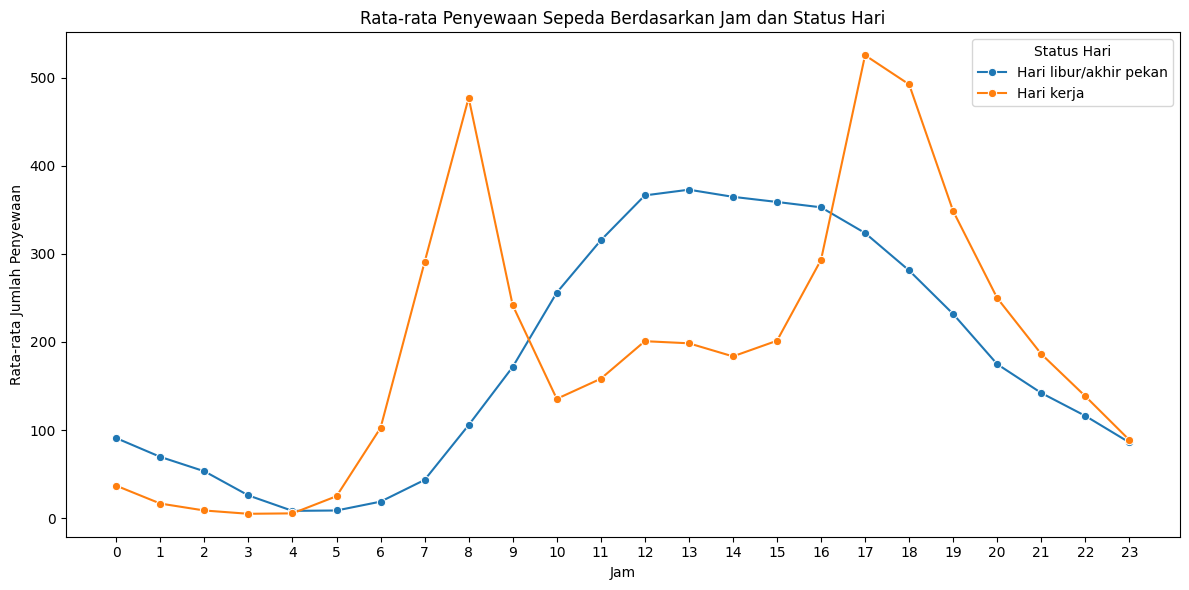

In [79]:
hourly_rentals = (
    hour_df.groupby(['hr', 'workingday'])['cnt']
    .mean()
    .reset_index()
)

hourly_rentals['status_hari'] = hourly_rentals['workingday'].map({
    0: 'Hari libur/akhir pekan',
    1: 'Hari kerja'
})

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_rentals,
    x='hr',
    y='cnt',
    hue='status_hari',
    marker='o'
)

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Jam dan Status Hari')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(0, 24))
plt.legend(title='Status Hari')
plt.tight_layout()
plt.show()

## Pertanyaan 2:

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca selama periode Januari 2011 hingga Desember 2012?

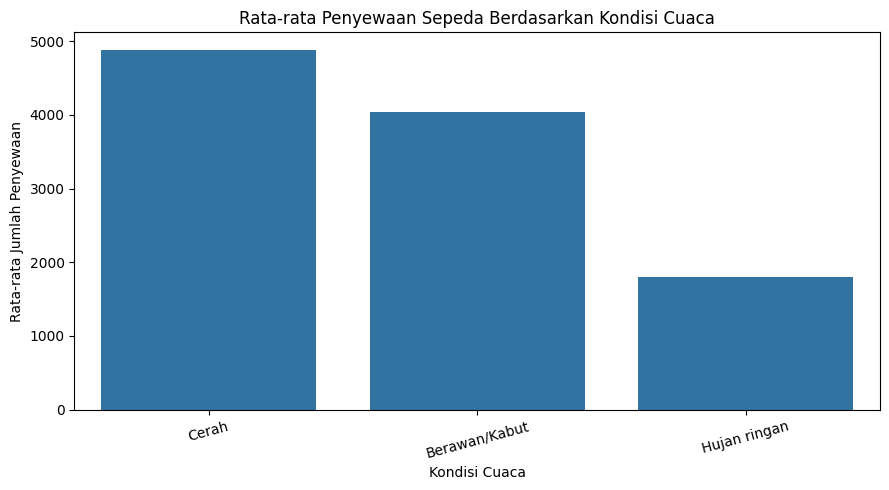

In [80]:
weather_rentals = (
    day_df.groupby('weathersit')['cnt']
    .mean()
    .reset_index()
)

weather_mapping = {
    1: 'Cerah',
    2: 'Berawan/Kabut',
    3: 'Hujan ringan',
    4: 'Hujan deras'
}

weather_rentals['weather_name'] = (
    weather_rentals['weathersit'].map(weather_mapping)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=weather_rentals,
    x='weather_name',
    y='cnt'
)

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

-Rata-rata penyewaan sepeda tertinggi terjadi pada kondisi cuaca cerah, yaitu sekitar 4.900 penyewaan.

-Pada kondisi berawan atau berkabut, rata-rata penyewaan sepeda sekitar 4.000 penyewaan.

-Rata-rata penyewaan terendah terjadi pada kondisi hujan ringan, yaitu sekitar 1.800 penyewaan.

-Hasil analisis menunjukkan bahwa jumlah penyewaan sepeda cenderung lebih tinggi saat cuaca cerah dibandingkan saat cuaca berawan atau hujan ringan.

## Analisis Lanjutan (Opsional)

### Analisis Korelasi Antarvariabel

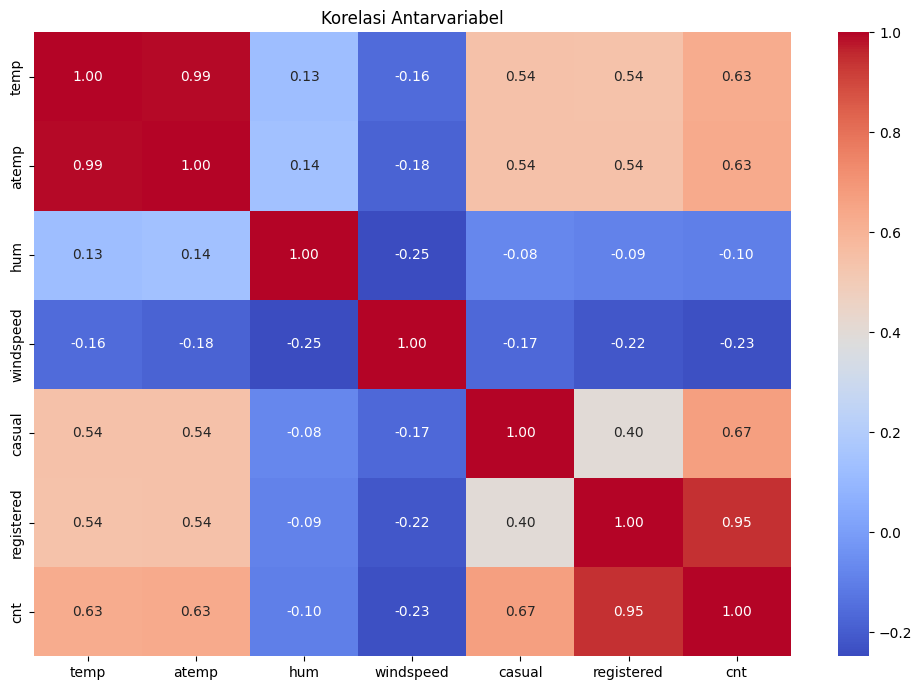

In [81]:
numeric_columns = [
    'temp',
    'atemp',
    'hum',
    'windspeed',
    'casual',
    'registered',
    'cnt'
]

correlation = day_df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Korelasi Antarvariabel')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Analisis korelasi digunakan untuk melihat hubungan antarvariabel numerik dalam dataset.
- Heatmap membantu mengidentifikasi variabel yang memiliki hubungan paling kuat dengan jumlah penyewaan sepeda.

In [82]:
print("Jumlah baris dan kolom day_df:", day_df.shape)
print("Jumlah baris dan kolom hour_df:", hour_df.shape)

print("\nTotal missing value day_df:")
print(day_df.isna().sum().sum())

print("\nTotal missing value hour_df:")
print(hour_df.isna().sum().sum())

print("\nJumlah duplikat day_df:", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

Jumlah baris dan kolom day_df: (731, 16)
Jumlah baris dan kolom hour_df: (17379, 17)

Total missing value day_df:
0

Total missing value hour_df:
0

Jumlah duplikat day_df: 0
Jumlah duplikat hour_df: 0


## Conclusion & Recommendation

## Conclusion

1. **Pola penyewaan berdasarkan jam dan status hari kerja:** Rata-rata penyewaan sepeda pada hari kerja mencapai puncaknya pada pukul 17.00, yaitu sekitar 525 penyewaan. Sementara itu, pada hari libur atau akhir pekan, puncak penyewaan terjadi pada pukul 13.00, yaitu sekitar 373 penyewaan. Rata-rata penyewaan terendah terjadi pada pukul 03.00 saat hari kerja dan pukul 04.00 saat hari libur atau akhir pekan.

2. **Pola penyewaan berdasarkan kondisi cuaca:** Rata-rata penyewaan tertinggi terjadi saat cuaca cerah, yaitu sekitar 4.900 penyewaan, diikuti kondisi berawan atau berkabut sekitar 4.000 penyewaan. Rata-rata penyewaan terendah terjadi saat hujan ringan, yaitu sekitar 1.800 penyewaan. Hasil ini menunjukkan adanya perbedaan jumlah penyewaan berdasarkan kondisi cuaca.

## Recommendation

1. **Pengelolaan ketersediaan sepeda:** Pengelola layanan bike sharing dapat menyesuaikan ketersediaan sepeda dan kebutuhan operasional berdasarkan jam dengan permintaan tinggi, terutama pukul 17.00 pada hari kerja dan pukul 13.00 pada hari libur atau akhir pekan.

2. **Perencanaan operasional berdasarkan cuaca:** Pengelola dapat mempertimbangkan kondisi cuaca dalam merencanakan ketersediaan sepeda dan kebutuhan operasional karena rata-rata penyewaan berbeda pada setiap kategori cuaca.

3. **Evaluasi pola permintaan:** Pengelola dapat menggunakan hasil analisis jam penyewaan dan kondisi cuaca sebagai bahan evaluasi untuk meningkatkan efisiensi operasional dan menyesuaikan layanan dengan pola permintaan pengguna.